# Machine Learning Based Heart Disease Prediction

This notebook predicts whether a patient has heart disease from clinical measurements. It covers data inspection and cleaning, exploratory data analysis (EDA), preprocessing, training of four classification models, evaluation, and a comparison of the results. The target variable is `target` (0 = no heart disease, 1 = heart disease).

The four models are Logistic Regression, Decision Tree, Random Forest and XGBoost.

**Important limitation.** This is an educational machine-learning project. It is not a clinically validated diagnostic tool. Do not use it to make medical decisions.

**How to run.** Use Run all, or run every cell from top to bottom in order. Later cells depend on variables created in earlier cells. Upload `Heart_Disease_Dataset.csv` to Colab (Files panel) or place it in your Google Drive under MyDrive before you start.

**AI assistance note.** Parts of this notebook were written with the assistance of Claude (Anthropic) and adapted for this dataset.

The sections are: 1. Setup and Imports, 2. Loading the Dataset, 3. Data Inspection and Cleaning, 4. Exploratory Data Analysis, 5. Data Preprocessing, 6. Model Training, 7. Model Evaluation, 8. Model Comparison and Discussion, 9. References.

## 1. Setup and Imports

All libraries are imported once, here. The main libraries are pandas (McKinney, 2010) and NumPy (Harris et al., 2020) for data handling, Matplotlib (Hunter, 2007) and seaborn (Waskom, 2021) for plots, scikit-learn (Pedregosa et al., 2011) for preprocessing, models and metrics, and XGBoost (Chen & Guestrin, 2016) for gradient boosting.

In [ ]:
# Data handling and numerical work
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Used to display tables and formatted text inside the notebook
from IPython.display import Markdown, display

# Splitting the data, cross-validation and the preprocessing pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import clone

# The four classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Evaluation metrics and plotting helpers
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    roc_auc_score,
)

# A clean, readable default style for every plot in the notebook
sns.set_theme(style="whitegrid")

## 2. Loading the Dataset

The data comes from the heart disease dataset file `Heart_Disease_Dataset.csv`. Add the full source citation for your download in section 9.

The cell below looks for the CSV file in the current folder, in `/content`, and in Google Drive (`MyDrive`). If it does not find the file, it mounts Google Drive (this works only in Google Colab). The file is read once and two copies are kept.

`raw_df` is the untouched source data. It is used for modelling, so nothing learned from the test set leaks into preprocessing.

`df` is a working copy that is cleaned and explored in sections 3 and 4.

In [ ]:
from pathlib import Path

# The file name uses spaces or underscores in different downloads, so a pattern replaces one fixed name
SEARCH_FOLDERS = [Path("."), Path("/content"), Path("/content/drive/MyDrive")]
FILE_PATTERN = "*eart*isease*.csv"


def find_dataset():
    """Return the path of the first CSV file that matches the pattern, or None."""
    for folder in SEARCH_FOLDERS:
        if folder.exists():
            matches = sorted(folder.glob(FILE_PATTERN))
            if matches:
                return matches[0]
    return None


csv_path = find_dataset()

# If the file was not found locally, try mounting Google Drive (Colab only)
if csv_path is None:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        csv_path = find_dataset()
    except ImportError:
        pass  # Not running in Colab, so there is no Drive to mount

if csv_path is None:
    raise FileNotFoundError(
        f"Could not find a CSV file that matches {FILE_PATTERN}. Place the file next to this "
        "notebook, in /content, or in Google Drive under MyDrive, then run again."
    )

raw_df = pd.read_csv(csv_path)  # untouched copy, used for modelling
df = raw_df.copy()              # working copy for cleaning and EDA

print("Loaded dataset from:", csv_path)
print("Dataset shape:", df.shape)

Loaded dataset from: /content/drive/MyDrive/Heart-Disease-Dataset.csv
Dataset shape: (1048, 13)


## 3. Data Inspection and Cleaning

This section checks the structure and quality of the data before any modelling. Cleaning steps are applied to the working copy `df` only. The modelling section starts again from `raw_df`.

### 3.1 Initial Dataset Inspection

In [ ]:
# First five rows: a quick look at the variables and how values are recorded
df.head()

,Unnamed: 0,age,sex,chest pain type,resting bps,cholesterol,fasting blood sugar,resting ecg,max heart rate,exercise angina,oldpeak,ST slope,target
0,0,40,1,2,140,289.0,0,0,172,0,0.0,1,0
1,1,49,0,3,160,180.0,0,0,156,0,1.0,2,1
2,2,37,1,2,130,283.0,0,1,98,0,0.0,1,0
3,3,48,0,4,138,214.0,0,0,108,1,1.5,2,1
4,4,54,1,3,150,195.0,0,0,122,0,0.0,1,0


In [ ]:
# Column names, data types, and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048 entries, 0 to 1047
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0           1048 non-null   int64  
 1   age                  1048 non-null   int64  
 2   sex                  1048 non-null   int64  
 3   chest pain type      1048 non-null   int64  
 4   resting bps          1048 non-null   int64  
 5   cholesterol          1048 non-null   float64
 6   fasting blood sugar  1048 non-null   int64  
 7   resting ecg          1048 non-null   int64  
 8   max heart rate       1048 non-null   int64  
 9   exercise angina      1048 non-null   int64  
 10  oldpeak              1048 non-null   float64
 11  ST slope             1048 non-null   int64  
 12  target               1048 non-null   int64  
dtypes: float64(2), int64(11)
memory usage: 106.6 KB


In [ ]:
# Summary statistics (count, mean, spread, quartiles) of the numerical variables
df.describe()

,Unnamed: 0,age,sex,chest pain type,resting bps,cholesterol,fasting blood sugar,resting ecg,max heart rate,exercise angina,oldpeak,ST slope,target
count,1048.000000,1048.000000,1048.000000,1048.000000,1048.000000,1048.000000,1048.000000,1048.000000,1048.000000,1048.000000,1048.000000,1048.000000,1048.000000
mean,390.841603,53.325382,0.734733,2.817748,132.613550,245.172710,0.162214,0.606870,142.918893,0.368321,0.942366,1.532443,0.496183
std,307.916633,9.397822,0.441686,1.118649,17.367605,57.101359,0.368823,0.763313,24.427115,0.482579,1.100429,0.611023,0.500224
min,0.000000,28.000000,0.000000,1.000000,92.000000,85.000000,0.000000,0.000000,69.000000,0.000000,-0.100000,0.000000,0.000000
25%,130.750000,46.000000,0.000000,2.000000,120.000000,208.000000,0.000000,0.000000,125.000000,0.000000,0.000000,1.000000,0.000000
50%,262.000000,54.000000,1.000000,3.000000,130.000000,239.000000,0.000000,0.000000,144.000000,0.000000,0.600000,2.000000,0.000000
75%,657.250000,60.000000,1.000000,4.000000,140.000000,275.000000,0.000000,1.000000,162.000000,1.000000,1.600000,2.000000,1.000000
max,1189.000000,77.000000,1.000000,4.000000,200.000000,603.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,1.000000


The dataset has 1,048 patient records and 13 columns. All columns are numeric. Several columns hold codes, not measurements. The table below explains each column.

| Column | Meaning |
|---|---|
| Unnamed: 0 | Leftover row number from an earlier file. Not a patient feature. |
| age | Age in years |
| sex | 1 = male, 0 = female |
| chest pain type | Coded 1 to 4: 1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic |
| resting bps | Resting blood pressure (mm Hg) |
| cholesterol | Serum cholesterol (mg/dl) |
| fasting blood sugar | 1 = above 120 mg/dl, 0 = at or below 120 mg/dl |
| resting ecg | Resting electrocardiogram result: 0 normal, 1 ST-T wave abnormality, 2 left ventricular hypertrophy |
| max heart rate | Highest heart rate reached (beats per minute) |
| exercise angina | 1 = exercise-induced angina, 0 = none |
| oldpeak | ST depression during exercise compared with rest |
| ST slope | Slope of the peak exercise ST segment, coded 0 to 3 |
| target | 1 = heart disease, 0 = no heart disease |

The code meanings follow the standard coding used for this family of heart disease datasets. Check them against the data dictionary from your source.

### 3.2 Checking Missing Values

In [ ]:
# Number and percentage of missing values in every column
missing_summary = pd.DataFrame({
    "Missing values": df.isnull().sum(),
    "Percentage (%)": (df.isnull().mean() * 100).round(2),
})
missing_summary

,Missing values,Percentage (%)
Unnamed: 0,0,0.0
age,0,0.0
sex,0,0.0
chest pain type,0,0.0
resting bps,0,0.0
cholesterol,0,0.0
fasting blood sugar,0,0.0
resting ecg,0,0.0
max heart rate,0,0.0
exercise angina,0,0.0


No column has missing values. The preprocessing pipeline in section 5 still includes imputation steps as a safeguard, so the same pipeline works on new data that has gaps.

### 3.3 Removing the Row-Number Column

The `Unnamed: 0` column holds row numbers left over from an earlier file. The next cell shows that its values repeat, so it does not identify patients. It says nothing about heart health and adds noise, so it is removed.

In [ ]:
# The leftover index column: the values run from 0 to 1189 but the file has only 1,048 rows
print("Rows in the file:", len(df))
print("Smallest and largest value:", df["Unnamed: 0"].min(), "and", df["Unnamed: 0"].max())
print("Values are unique:", df["Unnamed: 0"].is_unique)

# Drop it from the exploratory copy
df = df.drop(columns=["Unnamed: 0"])

# Check: this should print False
print("Index column still present:", "Unnamed: 0" in df.columns)
print("Current shape:", df.shape)

Rows in the file: 1048
Smallest and largest value: 0 and 1189
Values are unique: False
Index column still present: False
Current shape: (1048, 12)


### 3.4 Identifying Continuous and Coded Variables

All columns are stored as numbers, so the data type does not show which variables are continuous measurements and which are category codes. The split is made by hand from the data dictionary above.

Five variables are continuous measurements: age, resting bps, cholesterol, max heart rate and oldpeak.

Six variables are codes for categories: sex, chest pain type, fasting blood sugar, resting ecg, exercise angina and ST slope. Their numbers carry no arithmetic meaning. For example, chest pain type 4 is not twice chest pain type 2. These six are one-hot encoded in section 5.

In [ ]:
TARGET = "target"

# Continuous measurements
continuous_cols = ["age", "resting bps", "cholesterol", "max heart rate", "oldpeak"]

# Numeric codes that stand for categories
categorical_cols = [
    "sex", "chest pain type", "fasting blood sugar",
    "resting ecg", "exercise angina", "ST slope",
]

# Check that every column is assigned to exactly one group
assigned = set(continuous_cols) | set(categorical_cols) | {TARGET}
print("Columns not assigned to a group:", set(df.columns) - assigned)

# Frequency of each code in every categorical variable
for column in categorical_cols:
    print(f"\n{column}")
    print(df[column].value_counts().sort_index())

Columns not assigned to a group: set()

sex
sex
0    278
1    770
Name: count, dtype: int64

chest pain type
chest pain type
1    184
2    216
3    255
4    393
Name: count, dtype: int64

fasting blood sugar
fasting blood sugar
0    878
1    170
Name: count, dtype: int64

resting ecg
resting ecg
0    592
1    276
2    180
Name: count, dtype: int64

exercise angina
exercise angina
0    662
1    386
Name: count, dtype: int64

ST slope
ST slope
0     22
1    489
2    494
3     43
Name: count, dtype: int64


### 3.5 Checking for Duplicates

In [ ]:
# Number of fully duplicated rows (after the row-number column was removed)
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


No duplicate rows were found, so no records were removed. This matters for modelling. A duplicate that lands in both the training and the test set would inflate the test scores.

### 3.6 Checking the Target Balance

The balance of the target decides how the models are trained and judged.

Class counts:
target
0    528
1    520
Name: count, dtype: int64

Class percentages:
target
0    50.38
1    49.62
Name: proportion, dtype: float64


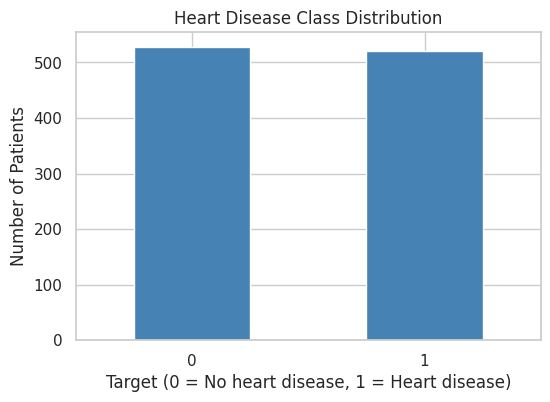

In [ ]:
# Class counts and percentages
print("Class counts:")
print(df[TARGET].value_counts().sort_index())
print("\nClass percentages:")
print((df[TARGET].value_counts(normalize=True).sort_index() * 100).round(2))

# Bar chart of the class distribution
plt.figure(figsize=(6, 4))
df[TARGET].value_counts().sort_index().plot(kind="bar", color="steelblue")
plt.title("Heart Disease Class Distribution")
plt.xlabel("Target (0 = No heart disease, 1 = Heart disease)")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.show()

The target is balanced. Of the 1,048 patients, 528 (50.38%) have no heart disease and 520 (49.62%) have heart disease. A model that always predicts the majority class scores about 50% accuracy, so accuracy is a fair first measure here. This differs from rare-event problems such as stroke prediction.

Class weights and resampling are not needed. Precision, recall and F1-score are still reported, because missing a patient with heart disease is the more serious error.

### 3.7 Checking for Impossible Values

Some medical datasets store a missing measurement as 0. A cholesterol or blood pressure of 0 is impossible for a living patient. The next cell counts these cases. It also counts negative `oldpeak` values.

In [ ]:
# Zero values in measurements that cannot be zero
print("Cholesterol equal to 0:", (df["cholesterol"] == 0).sum())
print("Resting bps equal to 0:", (df["resting bps"] == 0).sum())
print("Max heart rate equal to 0:", (df["max heart rate"] == 0).sum())

# Negative oldpeak values
print("\nOldpeak below 0:", (df["oldpeak"] < 0).sum())
print(df[df["oldpeak"] < 0])

# Smallest and largest value of each continuous variable
df[continuous_cols].agg(["min", "max"])

Cholesterol equal to 0: 0
Resting bps equal to 0: 0
Max heart rate equal to 0: 0

Oldpeak below 0: 1
     age  sex  chest pain type  resting bps  cholesterol  fasting blood sugar  \
345   35    1                3          123        161.0                    0   

     resting ecg  max heart rate  exercise angina  oldpeak  ST slope  target  
345            1             153                0     -0.1         1       0  


,age,resting bps,cholesterol,max heart rate,oldpeak
min,28,92,85.0,69,-0.1
max,77,200,603.0,202,6.2


No cholesterol, blood pressure or heart rate value equals 0, so no hidden missing values were found. One record has an `oldpeak` of -0.1. This value is tiny and close to zero. There is no evidence of a data-entry error, so the record was retained.

### 3.8 Detecting Numerical Outliers (IQR Method)

Outliers are checked for the five continuous variables. A value is flagged when it lies more than 1.5 times the interquartile range (IQR) below the first quartile or above the third quartile.

In [ ]:
# Quartiles and the IQR for each continuous variable
Q1 = df[continuous_cols].quantile(0.25)
Q3 = df[continuous_cols].quantile(0.75)
IQR = Q3 - Q1

# Standard 1.5 x IQR fences
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower bounds:")
print(lower_bound)
print("\nUpper bounds:")
print(upper_bound)

# Count how many values fall outside the fences in each column
outlier_counts = ((df[continuous_cols] < lower_bound) | (df[continuous_cols] > upper_bound)).sum()
print("\nNumber of potential outliers:")
print(outlier_counts)

Lower bounds:
age                25.0
resting bps        90.0
cholesterol       107.5
max heart rate     69.5
oldpeak            -2.4
dtype: float64

Upper bounds:
age                81.0
resting bps       170.0
cholesterol       375.5
max heart rate    217.5
oldpeak             4.0
dtype: float64

Number of potential outliers:
age                0
resting bps       29
cholesterol       28
max heart rate     1
oldpeak           11
dtype: int64


The IQR method found no outliers for age, 29 for resting bps, 28 for cholesterol, 1 for max heart rate and 11 for oldpeak. These records were retained. An IQR outlier is not always an error. Extreme blood pressure, cholesterol and ST depression readings are real clinical findings, and they carry information about heart disease. A record was removed only when there was evidence of a data-entry error, and none was found.

Logistic Regression is the model most sensitive to extreme values. Standardisation in section 5 limits their effect. The tree-based models are not affected by the scale of a value.

### 3.9 Final Data-Quality Check

In [ ]:
# One last look at the exploratory copy before the EDA
print("Dataset shape:", df.shape)
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nColumns:", df.columns.tolist())

Dataset shape: (1048, 12)

Missing values per column:
age                    0
sex                    0
chest pain type        0
resting bps            0
cholesterol            0
fasting blood sugar    0
resting ecg            0
max heart rate         0
exercise angina        0
oldpeak                0
ST slope               0
target                 0
dtype: int64

Duplicate rows: 0

Columns: ['age', 'sex', 'chest pain type', 'resting bps', 'cholesterol', 'fasting blood sugar', 'resting ecg', 'max heart rate', 'exercise angina', 'oldpeak', 'ST slope', 'target']


## 4. Exploratory Data Analysis

Exploratory data analysis (EDA) examines distributions, category frequencies and the link between each feature and heart disease. The plots describe the data. They do not prove causation. The exploratory copy `df` is used here. The modelling section uses the untouched `raw_df` with a leakage-safe preprocessing pipeline.

### 4.1 Continuous Features

#### Distribution of Age

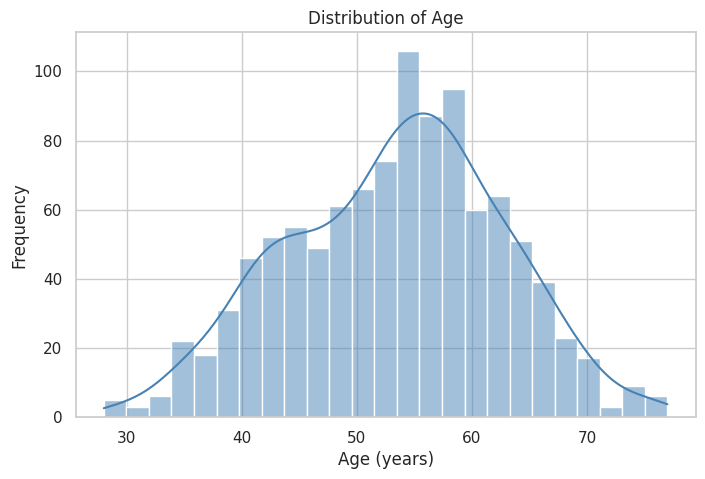

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="age", bins=25, kde=True, color="steelblue")
plt.title("Distribution of Age")
plt.xlabel("Age (years)")
plt.ylabel("Frequency")
plt.show()

**Observation: age.** Ages run from 28 to 77 with a mean of 53.3 years. The shape is close to symmetric (skewness -0.14), and no value is flagged as an outlier. Most patients are between 46 and 60. Age is a known risk factor for heart disease, so it is kept and standardised during preprocessing.

#### Distribution of Resting Blood Pressure

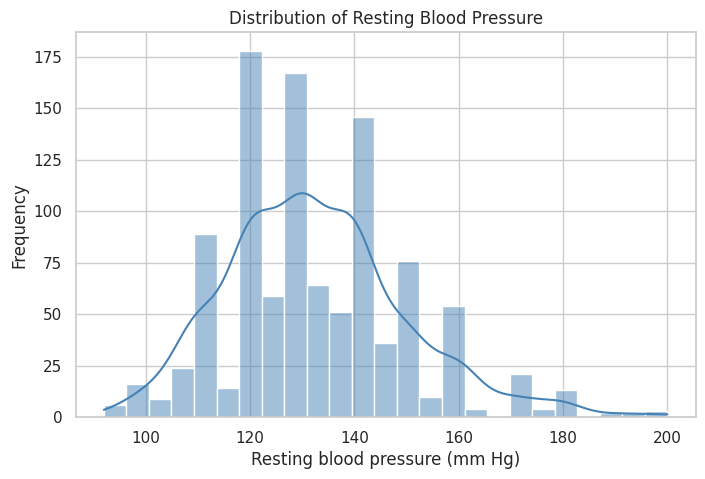

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="resting bps", bins=25, kde=True, color="steelblue")
plt.title("Distribution of Resting Blood Pressure")
plt.xlabel("Resting blood pressure (mm Hg)")
plt.ylabel("Frequency")
plt.show()

**Observation: resting blood pressure.** The median is 130 mm Hg and the mean is 132.6. Values run from 92 to 200. The distribution is mildly right-skewed (0.64), and the 29 flagged values are high blood pressure readings. These are plausible patient values, so they were retained.

#### Distribution of Cholesterol

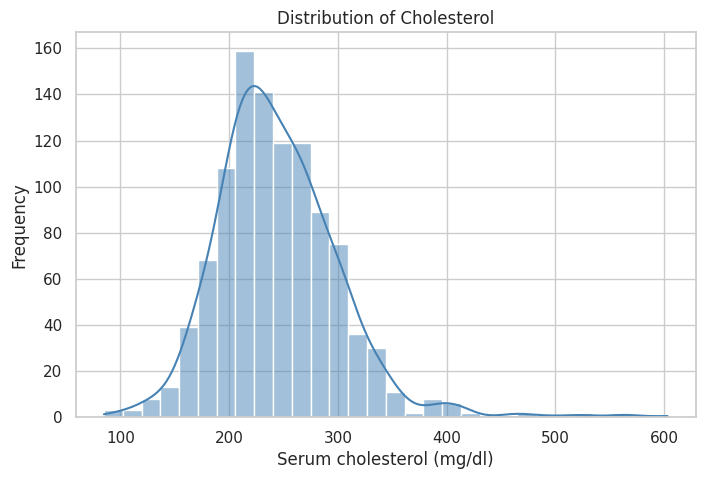

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="cholesterol", bins=30, kde=True, color="steelblue")
plt.title("Distribution of Cholesterol")
plt.xlabel("Serum cholesterol (mg/dl)")
plt.ylabel("Frequency")
plt.show()

**Observation: cholesterol.** The median is 239 mg/dl and the mean is 245.2. The distribution is right-skewed (1.22). A few patients have extreme values, with a maximum of 603. These readings are medically possible, so the 28 flagged values were retained. Standardisation brings cholesterol onto the same scale as the other features.

#### Distribution of Maximum Heart Rate

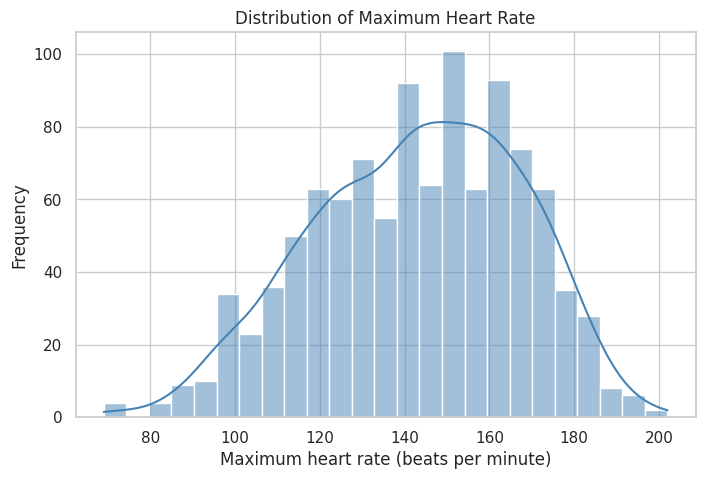

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="max heart rate", bins=25, kde=True, color="steelblue")
plt.title("Distribution of Maximum Heart Rate")
plt.xlabel("Maximum heart rate (beats per minute)")
plt.ylabel("Frequency")
plt.show()

**Observation: maximum heart rate.** The distribution is close to symmetric (skewness -0.27) with a mean of 142.9 beats per minute. Values run from 69 to 202. Only one value is flagged as an outlier. Maximum heart rate falls with age and with heart disease, so it is a useful predictor.

#### Distribution of Oldpeak (ST Depression)

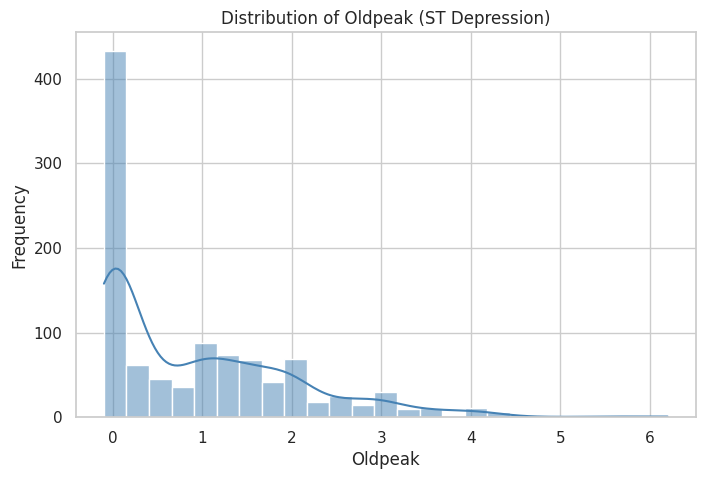

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="oldpeak", bins=25, kde=True, color="steelblue")
plt.title("Distribution of Oldpeak (ST Depression)")
plt.xlabel("Oldpeak")
plt.ylabel("Frequency")
plt.show()

**Observation: oldpeak.** Many patients sit at or near 0, and a long tail runs to 6.2. The distribution is strongly right-skewed (1.24). The median is 0.6 and the mean is 0.94. The tail holds the 11 flagged values. ST depression of this size is a clinical warning sign, so these records were kept.

### 4.2 Coded Categorical Features

Each plot below shows how many patients fall into each code, split by the target. This shows the size of every group and its heart disease rate in one view.

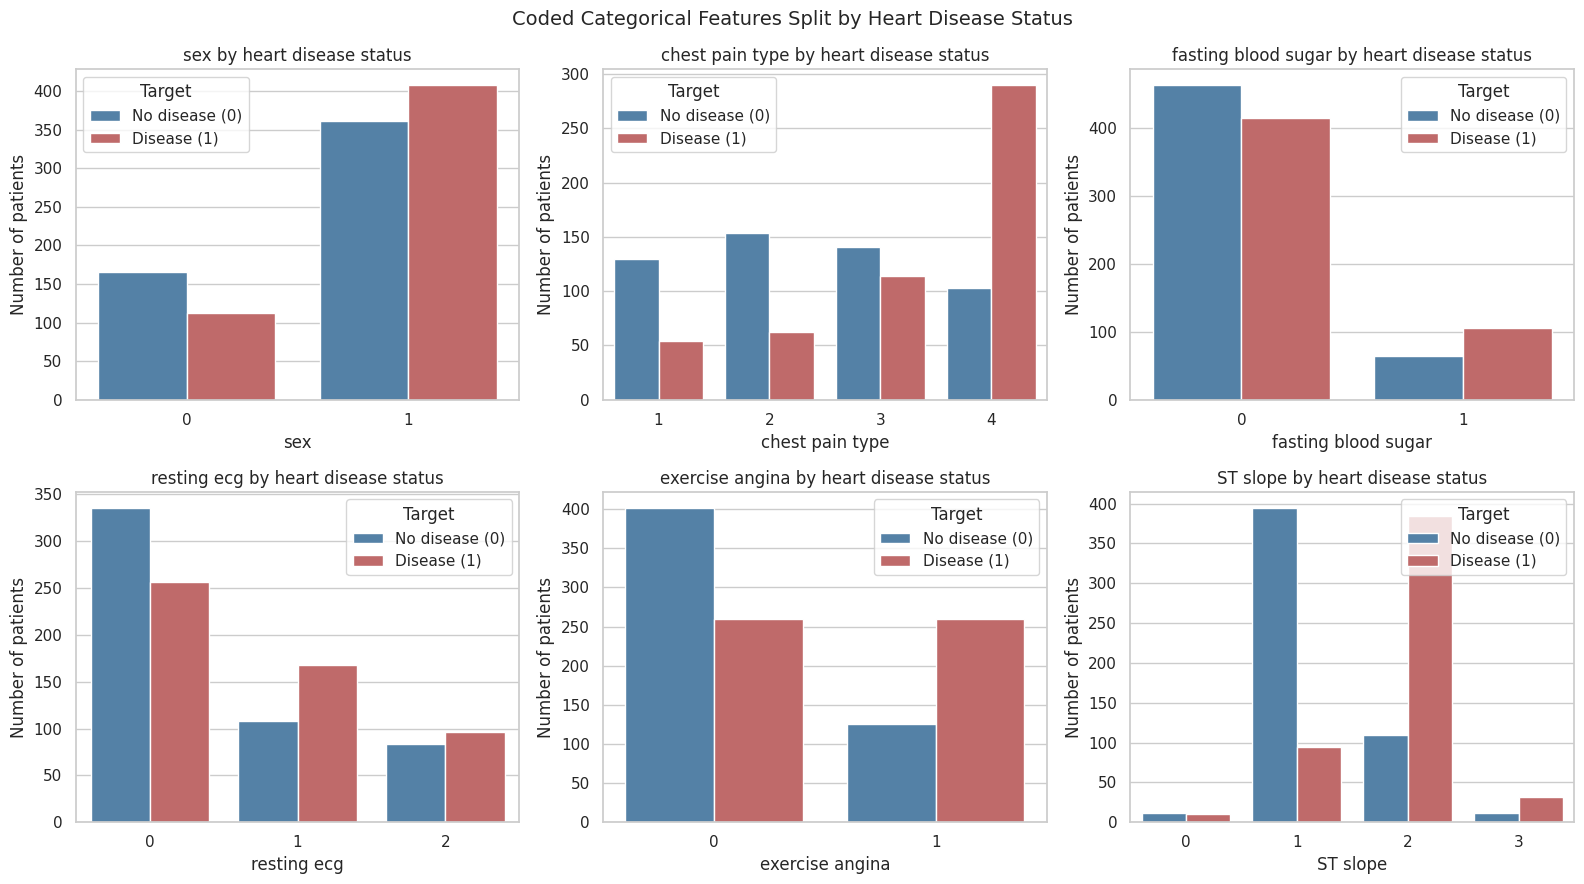

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, column in zip(axes.ravel(), categorical_cols):
    sns.countplot(data=df, x=column, hue=TARGET, palette=["steelblue", "indianred"], ax=ax)
    ax.set_title(f"{column} by heart disease status")
    ax.set_xlabel(column)
    ax.set_ylabel("Number of patients")
    ax.legend(title="Target", labels=["No disease (0)", "Disease (1)"])

fig.suptitle("Coded Categorical Features Split by Heart Disease Status", fontsize=14)
fig.tight_layout()
plt.show()

In [ ]:
# Heart disease rate (share of patients with target = 1) in each group of each coded feature
for column in categorical_cols:
    rate_table = df.groupby(column)[TARGET].agg(["mean", "count"]).round(3)
    rate_table.columns = ["Heart disease rate", "Patients"]
    print(f"\n{column}")
    print(rate_table)


sex
     Heart disease rate  Patients
sex                              
0                 0.403       278
1                 0.530       770

chest pain type
                 Heart disease rate  Patients
chest pain type                              
1                             0.293       184
2                             0.287       216
3                             0.447       255
4                             0.738       393

fasting blood sugar
                     Heart disease rate  Patients
fasting blood sugar                              
0                                 0.473       878
1                                 0.618       170

resting ecg
             Heart disease rate  Patients
resting ecg                              
0                         0.432       592
1                         0.609       276
2                         0.533       180

exercise angina
                 Heart disease rate  Patients
exercise angina                              
0            

**Observation: sex.** The data holds 770 men (73.5%) and 278 women. The heart disease rate is 53.0% for men and 40.3% for women. Women are under-represented, so the models learn less about them.

**Observation: chest pain type.** This feature separates the classes strongly. The disease rate is 29.3% for type 1, 28.7% for type 2, 44.7% for type 3 and 73.8% for type 4 (asymptomatic). Type 4 is the largest group with 393 patients. Many patients with heart disease report no chest pain.

**Observation: fasting blood sugar.** Only 170 patients (16.2%) have high fasting blood sugar. Their disease rate is 61.8% against 47.3% for the others. The link is modest.

**Observation: resting ecg.** Normal results (0) are the largest group with 592 patients and a 43.2% disease rate. Code 1 has 60.9% and code 2 has 53.3%. Abnormal results carry a higher disease rate than normal ones, and the gap reaches 18 points for code 1.

**Observation: exercise angina.** Patients with exercise-induced angina have a 67.4% disease rate against 39.3% for those without it. This is a clear and useful signal.

**Observation: ST slope.** This is the strongest categorical signal. Codes 1 and 2 hold most patients (489 and 494). The disease rate is 19.2% for code 1 and 77.7% for code 2. Code 3 has 74.4%. Code 0 has only 22 patients (45.5%), which is too few to judge. Each code is one-hot encoded so the models treat the codes separately.

### 4.3 Relationships With the Target

#### Correlation Heatmap

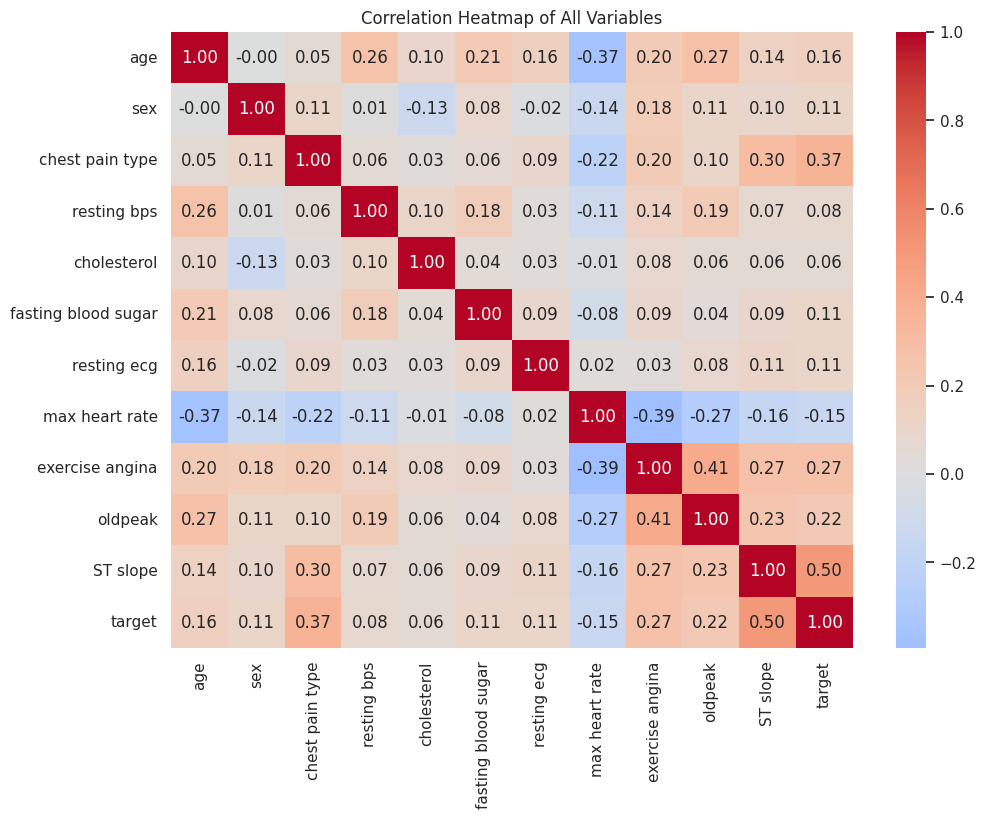

In [ ]:
# Pearson correlation between all variables (including the target)
correlation_matrix = df.corr()

plt.figure(figsize=(11, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of All Variables")
plt.show()

**Observation: correlations.** ST slope has the strongest linear link to heart disease (0.50), followed by chest pain type (0.37), exercise angina (0.27) and oldpeak (0.22). Age (0.16) and sex (0.11) are weaker. Max heart rate has a negative link (-0.15). Cholesterol (0.06) and resting bps (0.08) are the weakest.

Correlation treats a code as a number, so the values for chest pain type, ST slope and the other coded features are rough guides only. A weak correlation does not make a feature useless, because the models detect non-linear and interaction effects. All features are kept for modelling.

#### Continuous Features by Heart Disease Status

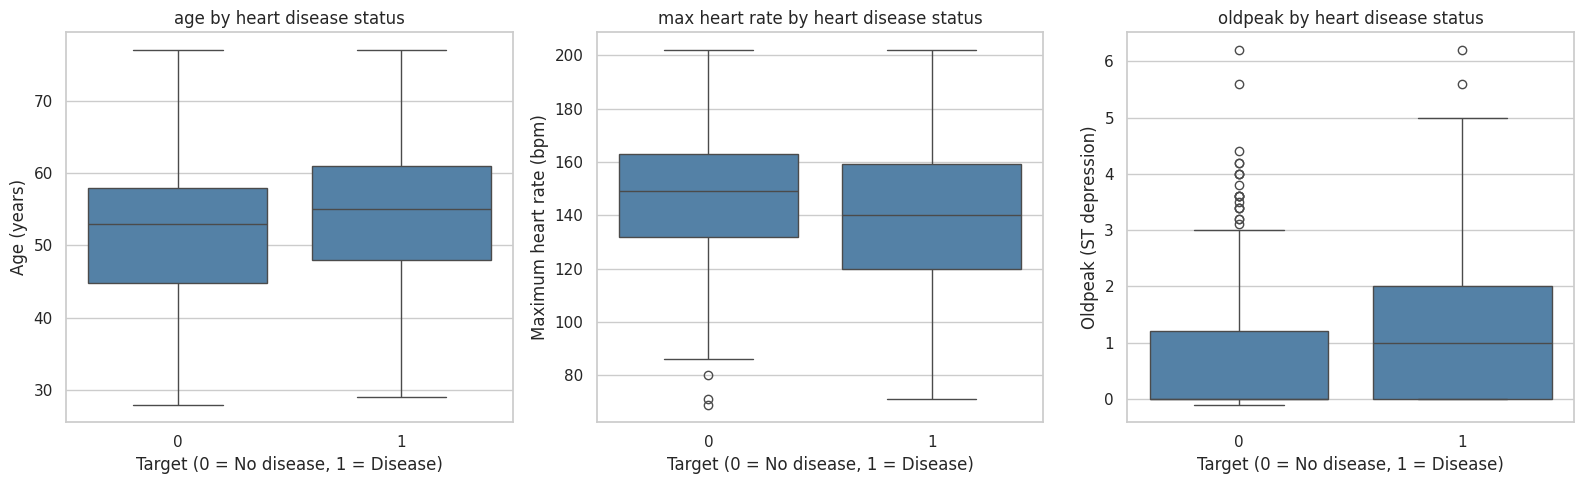

,age,resting bps,cholesterol,max heart rate,oldpeak
target,,,,,
0,53.0,130.0,236.0,149.0,0.0
1,55.0,132.0,242.0,140.0,1.0


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, column, label in zip(
    axes,
    ["age", "max heart rate", "oldpeak"],
    ["Age (years)", "Maximum heart rate (bpm)", "Oldpeak (ST depression)"],
):
    sns.boxplot(data=df, x=TARGET, y=column, color="steelblue", ax=ax)
    ax.set_title(f"{column} by heart disease status")
    ax.set_xlabel("Target (0 = No disease, 1 = Disease)")
    ax.set_ylabel(label)

fig.tight_layout()
plt.show()

# Median of every continuous variable in each group
df.groupby(TARGET)[continuous_cols].median()

**Observation: continuous features and heart disease.** Patients with heart disease have a lower median maximum heart rate (140 against 149 beats per minute) and a higher median oldpeak (1.0 against 0.0). The median age is only a little higher (55 against 53), so age alone does not separate the groups. The boxes overlap for every feature, so no single measurement predicts heart disease. The models must combine several features.

## 5. Data Preprocessing

For modelling, the notebook returns to `raw_df`, which keeps the source data from before any exploratory changes. The steps are:

1. Separate the target from the features and remove the `Unnamed: 0` row-number column.
2. Split into training and test sets (80% and 20%, stratified so both sets keep the same class balance).
3. Build a preprocessing pipeline that fills missing values, scales continuous features and one-hot encodes coded categorical features. It is fitted on the training data only and then applied to the test data.

Doing the split first and fitting every preprocessing step on the training set only prevents data leakage from the test set.

### 5.1 Train/Test Split

In [ ]:
# Features (everything except the target and the row-number column) and the target
X = raw_df.drop(columns=[TARGET, "Unnamed: 0"], errors="ignore")
y = raw_df[TARGET].astype(int)

# 80/20 split. stratify=y keeps the class balance the same in both sets,
# and random_state makes the split reproducible.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training features shape:", X_train.shape)
print("Test features shape:    ", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())
print("\nTest target distribution:")
print(y_test.value_counts().sort_index())

Training features shape: (838, 11)
Test features shape:     (210, 11)

Training target distribution:
target
0    422
1    416
Name: count, dtype: int64

Test target distribution:
target
0    106
1    104
Name: count, dtype: int64


### 5.2 Preprocessing Pipeline

Continuous features are filled with the training-set median and then standardised to mean 0 and standard deviation 1. Standardisation matters most for Logistic Regression, which is sensitive to feature scale.

Coded categorical features are filled with their most frequent training value and one-hot encoded. One-hot encoding is used because the codes have no numeric order. `handle_unknown="ignore"` lets the pipeline cope with a code that appears in the test set but not in training.

The target is balanced, so no class weights are used.

Each model gets its own copy of the pipeline (through `clone`), so no preprocessing step is ever fitted on the test set.

In [ ]:
# Column groups (set by hand in section 3.4 because every column is stored as a number)
numeric_features = continuous_cols
categorical_features = categorical_cols

# Continuous branch: fill missing values with the training median, then standardise
numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Categorical branch: fill with the most frequent value, then one-hot encode
categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

# Apply each branch to its own columns
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features),
])

print("Continuous features: ", numeric_features)
print("Categorical features:", categorical_features)

Continuous features:  ['age', 'resting bps', 'cholesterol', 'max heart rate', 'oldpeak']
Categorical features: ['sex', 'chest pain type', 'fasting blood sugar', 'resting ecg', 'exercise angina', 'ST slope']


## 6. Model Training

Four models are trained on the same training set and evaluated on the same stratified test set: Logistic Regression, Decision Tree, Random Forest and XGBoost. Settings are fixed and sensible. No hyperparameter tuning was done, so this is a comparison of baseline models. A fixed random seed of 42 makes the results reproducible.

Logistic Regression is the baseline. It is simple, fast and easy to interpret, and it draws a straight-line boundary between the classes. It runs for up to 2,000 iterations so the solver converges.

The Decision Tree is easy to explain. It asks a series of yes-or-no questions about the patient. All settings are default, so the tree has no depth limit. Expect it to fit the training data closely.

The Random Forest builds 200 trees on random samples of the data and combines their votes. It captures non-linear patterns and interactions between features, such as chest pain type together with ST slope.

XGBoost builds 200 shallow trees one after another, and each tree corrects the errors of the earlier ones. The learning rate is 0.05, the maximum depth is 4, and each tree sees 90% of the rows and columns. The low rate and the sampling reduce overfitting.

In [ ]:
# Each model is a pipeline: preprocessing first, then the classifier.
# clone(preprocessor) gives every model its own unfitted copy of the preprocessing.
models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(max_iter=2000, random_state=42)),
    ]),
    "Decision Tree": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", DecisionTreeClassifier(random_state=42)),
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)),
    ]),
    "XGBoost": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", XGBClassifier(
            n_estimators=200,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.9,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1,
        )),
    ]),
}

# Fit every pipeline on the training data only
for model_name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{model_name}: training complete")

Logistic Regression: training complete
Decision Tree: training complete
Random Forest: training complete
XGBoost: training complete


In [ ]:
import joblib

joblib.dump(models["Logistic Regression"], "logistic_regression_pipeline.joblib")
joblib.dump(models["Decision Tree"], "decision_tree_pipeline.joblib")
joblib.dump(models["Random Forest"], "random_forest_pipeline.joblib")
joblib.dump(models["XGBoost"], "xgboost_pipeline.joblib")

from google.colab import files

for filename in [
    "logistic_regression_pipeline.joblib",
    "decision_tree_pipeline.joblib",
    "random_forest_pipeline.joblib",
    "xgboost_pipeline.joblib",
]:
    files.download(filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Model Evaluation

All four models are evaluated on the same stratified test set of 210 patients. For each model, the notebook reports accuracy, precision, recall and F1-score for each class, specificity, the confusion matrix, and two threshold-independent scores (ROC-AUC and PR-AUC).

The positive class is heart disease (class 1). A false negative is a patient with heart disease whom the model clears. This is the more serious error, so recall for class 1 gets the most attention. Specificity is the share of healthy patients the model clears correctly. It shows the cost of a high recall in false alarms.

This is an educational comparison, not a clinical tool.

### 7.1 Calculating the Metrics

The cell below predicts the test set with every model. It calculates the confusion matrix and the per-class scores for each one. It also adds a 95% Wilson confidence interval for recall (Wilson, 1927), which shows how uncertain a score from a small test set is.

In [ ]:
# All four trained models in one place so a loop evaluates them together
trained_models = {name: model for name, model in models.items()}
CLASS_NAMES = {0: "No disease (0)", 1: "Heart disease (1)"}


def wilson_interval(successes, n, z=1.96):
    """95% Wilson confidence interval for a proportion (used for disease recall)."""
    p = successes / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half


confusion_matrices, scores = {}, {}
summary_rows, class_rows = [], []

for name, model in trained_models.items():
    # Class predictions (0.5 cut-off) and predicted disease probabilities
    y_pred = model.predict(X_test)
    y_score = model.predict_proba(X_test)[:, 1]
    scores[name] = y_score

    # Confusion matrix: rows = actual class, columns = predicted class.
    # ravel() returns true negatives, false positives, false negatives, true positives.
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    confusion_matrices[name] = cm
    tn, fp, fn, tp = cm.ravel()

    # Precision, recall, F1-score and support for each class (index 0 and 1)
    precision, recall, f1, support = precision_recall_fscore_support(
        y_test, y_pred, labels=[0, 1], zero_division=0
    )

    # Uncertainty of disease recall: the patients with heart disease are tp + fn
    ci_low, ci_high = wilson_interval(tp, tp + fn)

    # One row per model for the overall comparison table
    summary_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Disease precision": precision[1],
        "Disease recall": recall[1],
        "Disease F1": f1[1],
        "Specificity": recall[0],
        "Disease recall 95% CI": f"{ci_low:.2f} to {ci_high:.2f}",
        "Macro F1": f1.mean(),
        "ROC-AUC": roc_auc_score(y_test, y_score),
        "PR-AUC": average_precision_score(y_test, y_score),
        "TP": tp, "FN": fn, "FP": fp, "TN": tn,
    })

    # Two rows per model (one per class) for the per-class table
    for label in (0, 1):
        class_rows.append({
            "Model": name,
            "Class": CLASS_NAMES[label],
            "Precision": precision[label],
            "Recall": recall[label],
            "F1-score": f1[label],
            "Support": int(support[label]),
        })

summary_df = pd.DataFrame(summary_rows)
class_df = pd.DataFrame(class_rows)

# Reference points for judging the results
majority_accuracy = max((y_test == 0).mean(), (y_test == 1).mean())  # always predict the larger class
disease_prevalence = y_test.mean()                                   # precision of random guessing

print(f"Test set: {len(y_test)} patients ({int(y_test.sum())} with heart disease)")
print(f"Baseline accuracy (always predict the larger class): {majority_accuracy:.4f}")
print(f"Disease prevalence (precision of random guessing): {disease_prevalence:.4f}\n")

print("Overall comparison (TP/FN/FP/TN = confusion-matrix counts for the disease class):")
display(summary_df.round(4))
print("\nPer-class precision, recall and F1-score:")
display(class_df.round(4))

Test set: 210 patients (104 with heart disease)
Baseline accuracy (always predict the larger class): 0.5048
Disease prevalence (precision of random guessing): 0.4952

Overall comparison (TP/FN/FP/TN = confusion-matrix counts for the disease class):


,Model,Accuracy,Disease precision,Disease recall,Disease F1,Specificity,Disease recall 95% CI,Macro F1,ROC-AUC,PR-AUC,TP,FN,FP,TN
0,Logistic Regression,0.8143,0.8095,0.8173,0.8134,0.8113,0.73 to 0.88,0.8143,0.8777,0.8669,85,19,20,86
1,Decision Tree,0.7762,0.7664,0.7885,0.7773,0.7642,0.70 to 0.86,0.7762,0.7763,0.7090,82,22,25,81
2,Random Forest,0.8524,0.8614,0.8365,0.8488,0.8679,0.75 to 0.90,0.8523,0.9061,0.9126,87,17,14,92
3,XGBoost,0.8190,0.8173,0.8173,0.8173,0.8208,0.73 to 0.88,0.8190,0.8861,0.8830,85,19,19,87



Per-class precision, recall and F1-score:


,Model,Class,Precision,Recall,F1-score,Support
0,Logistic Regression,No disease (0),0.8190,0.8113,0.8152,106
1,Logistic Regression,Heart disease (1),0.8095,0.8173,0.8134,104
2,Decision Tree,No disease (0),0.7864,0.7642,0.7751,106
3,Decision Tree,Heart disease (1),0.7664,0.7885,0.7773,104
4,Random Forest,No disease (0),0.8440,0.8679,0.8558,106
5,Random Forest,Heart disease (1),0.8614,0.8365,0.8488,104
6,XGBoost,No disease (0),0.8208,0.8208,0.8208,106
7,XGBoost,Heart disease (1),0.8173,0.8173,0.8173,104


### 7.2 Confusion Matrices

Rows are the actual class and columns are the predicted class. The bottom-left cell is the number of patients with heart disease whom the model missed (false negatives). The first grid shows counts. The second grid shows the share of each actual class, so the bottom-right value is the disease recall and the top-left value is the specificity.

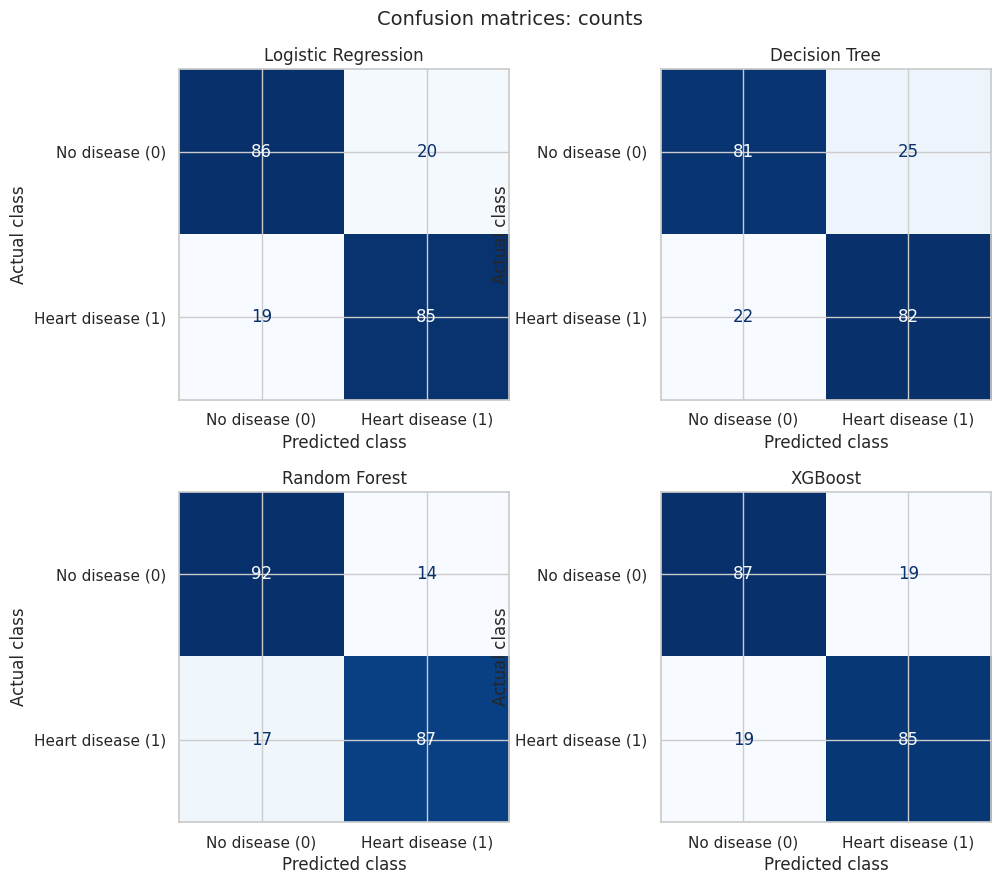

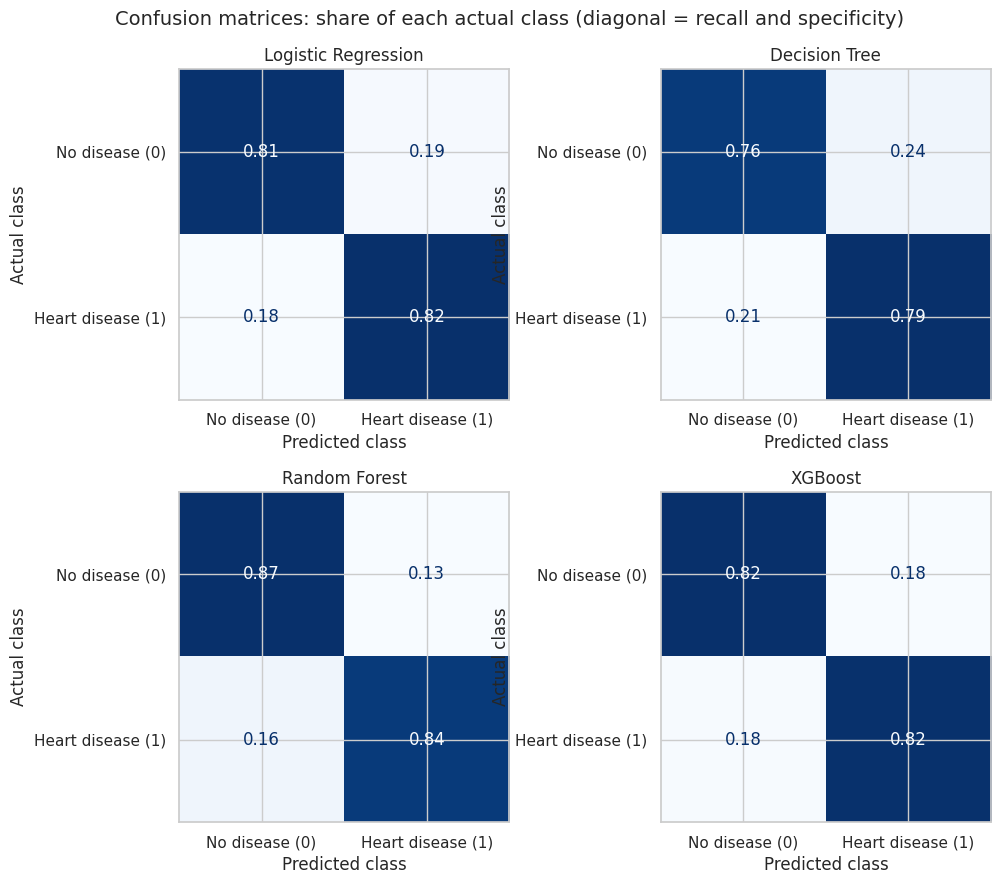

In [ ]:
labels = [CLASS_NAMES[0], CLASS_NAMES[1]]

# Draw the same 2x2 grid twice: first with counts, then with row-normalised values
grid_configs = [
    ("Confusion matrices: counts", False),
    ("Confusion matrices: share of each actual class (diagonal = recall and specificity)", True),
]
for title, normalise in grid_configs:
    fig, axes = plt.subplots(2, 2, figsize=(10, 9))

    # One panel per model
    for ax, (name, cm) in zip(axes.ravel(), confusion_matrices.items()):
        # Normalising divides each row by its total, so each row sums to 1
        values = cm / cm.sum(axis=1, keepdims=True) if normalise else cm
        ConfusionMatrixDisplay(values, display_labels=labels).plot(
            ax=ax, cmap="Blues", colorbar=False,
            values_format=".2f" if normalise else "d",
        )
        ax.set_title(name)
        ax.set_xlabel("Predicted class")
        ax.set_ylabel("Actual class")

    fig.suptitle(title, fontsize=14)
    fig.tight_layout()
    plt.show()

### 7.3 Visual Model Comparison

The bar chart compares disease-class precision, recall and F1-score across the four models. The ROC and precision-recall curves show how well each model separates patients with and without heart disease across all possible thresholds, not only at 0.5. On the precision-recall plot, the dashed line is the performance of random guessing. A curve that stays close to it has little ranking ability.

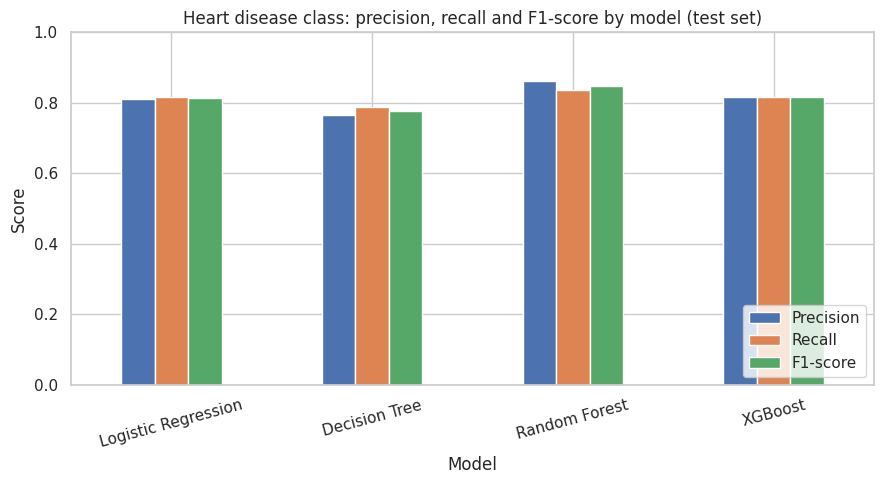

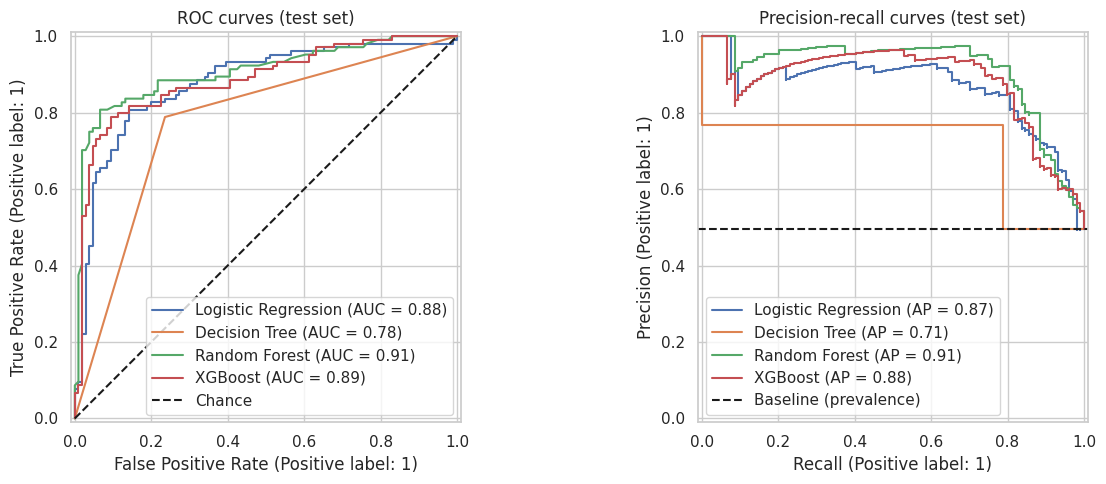

In [ ]:
# Disease-class (class 1) precision, recall and F1-score for each model
disease_metrics = (
    class_df[class_df["Class"] == CLASS_NAMES[1]]
    .set_index("Model")[["Precision", "Recall", "F1-score"]]
)

# Grouped bar chart of the three metrics
ax = disease_metrics.plot(kind="bar", figsize=(9, 5), ylim=(0, 1))
ax.set_title("Heart disease class: precision, recall and F1-score by model (test set)")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# ROC curves (left) and precision-recall curves (right), all four models on each
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, y_score in scores.items():
    RocCurveDisplay.from_predictions(y_test, y_score, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, y_score, name=name, ax=axes[1])

# Reference lines: chance level for ROC, disease prevalence for precision-recall
axes[0].plot([0, 1], [0, 1], "k--", label="Chance")
axes[0].set_title("ROC curves (test set)")
axes[1].axhline(disease_prevalence, color="k", linestyle="--", label="Baseline (prevalence)")
axes[1].set_title("Precision-recall curves (test set)")
for ax in axes:
    ax.legend(loc="best")
plt.tight_layout()
plt.show()

### 7.4 Training Accuracy Against Test Accuracy

A model that scores far higher on the training data than on the test data has memorised the training data. The gap between the two scores shows overfitting. The Decision Tree and the Random Forest grow deep trees with default settings, so check them first.

,Model,Training accuracy,Test accuracy,Gap
0,Logistic Regression,0.7959,0.8143,-0.0183
1,Decision Tree,1.0000,0.7762,0.2238
2,Random Forest,1.0000,0.8524,0.1476
3,XGBoost,0.9284,0.8190,0.1094


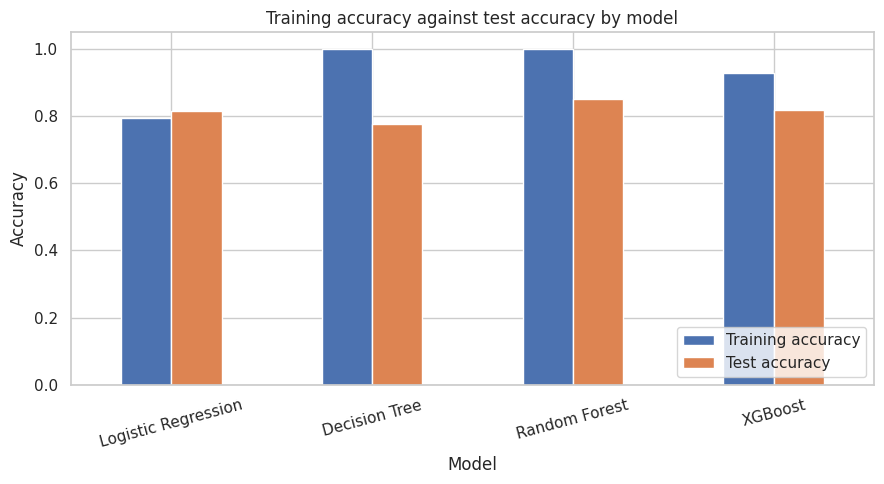

In [ ]:
# Accuracy of each model on the data it learned from and on the unseen test data
fit_rows = []
for name, model in trained_models.items():
    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))
    fit_rows.append({
        "Model": name,
        "Training accuracy": train_acc,
        "Test accuracy": test_acc,
        "Gap": train_acc - test_acc,
    })

fit_df = pd.DataFrame(fit_rows)
display(fit_df.round(4))

# Bar chart of the two accuracy scores for each model
ax = fit_df.set_index("Model")[["Training accuracy", "Test accuracy"]].plot(
    kind="bar", figsize=(9, 5), ylim=(0, 1.05)
)
ax.set_title("Training accuracy against test accuracy by model")
ax.set_xlabel("Model")
ax.set_ylabel("Accuracy")
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 7.5 Cross-Validation Check

The test set holds only 210 patients, so one patient moves a score by about half a percentage point. A second check makes the comparison more reliable. Each model is trained and scored five times on different parts of the training data (stratified 5-fold cross-validation). The test set stays untouched. Stable scores across folds show that a result does not depend on one lucky split.

No settings are tuned here. The check only measures how steady each model is.

In [ ]:
# 5-fold stratified cross-validation on the training data only
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scoring = {"accuracy": "accuracy", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

cv_rows = []
for name, model in models.items():
    # clone() gives a fresh, unfitted copy so the trained models above are not changed
    results = cross_validate(clone(model), X_train, y_train, cv=cv, scoring=cv_scoring)
    cv_rows.append({
        "Model": name,
        "CV accuracy": f"{results['test_accuracy'].mean():.3f} (+/- {results['test_accuracy'].std():.3f})",
        "CV recall": f"{results['test_recall'].mean():.3f} (+/- {results['test_recall'].std():.3f})",
        "CV F1": f"{results['test_f1'].mean():.3f} (+/- {results['test_f1'].std():.3f})",
        "CV ROC-AUC": f"{results['test_roc_auc'].mean():.3f} (+/- {results['test_roc_auc'].std():.3f})",
    })

cv_df = pd.DataFrame(cv_rows)
display(cv_df)

,Model,CV accuracy,CV recall,CV F1,CV ROC-AUC
0,Logistic Regression,0.792 (+/- 0.012),0.801 (+/- 0.021),0.793 (+/- 0.010),0.852 (+/- 0.017)
1,Decision Tree,0.699 (+/- 0.022),0.678 (+/- 0.076),0.689 (+/- 0.039),0.699 (+/- 0.022)
2,Random Forest,0.802 (+/- 0.018),0.805 (+/- 0.016),0.802 (+/- 0.016),0.871 (+/- 0.007)
3,XGBoost,0.782 (+/- 0.017),0.796 (+/- 0.037),0.783 (+/- 0.016),0.844 (+/- 0.012)


### 7.6 Results Summary

The cell below reads the tables above and writes a short summary of which model scored highest on each metric. It also flags models that overfit and models no better than the baseline. The text is generated from the results, so it stays correct when you run the notebook again.

In [ ]:
# Index the summary table by model name for easy lookup
s = summary_df.set_index("Model")
fit = fit_df.set_index("Model")

# Models no more accurate than always predicting the larger class
at_or_below_baseline = [m for m in s.index if s.loc[m, "Accuracy"] <= majority_accuracy]

# Models that score at least 0.10 higher on the training data than on the test data
overfitting_models = [m for m in fit.index if fit.loc[m, "Gap"] >= 0.10]

best_recall_model = s["Disease recall"].idxmax()
lines = [
    "#### Results summary (generated from the tables above)",
    f"**Highest disease recall:** {best_recall_model} ({s['Disease recall'].max():.2f}, "
    f"{int(s.loc[best_recall_model, 'FN'])} missed patients with heart disease).",
    f"**Highest disease precision:** {s['Disease precision'].idxmax()} ({s['Disease precision'].max():.2f}).",
    f"**Highest disease F1-score:** {s['Disease F1'].idxmax()} ({s['Disease F1'].max():.2f}).",
    f"**Highest specificity:** {s['Specificity'].idxmax()} ({s['Specificity'].max():.2f}).",
    f"**Highest ROC-AUC:** {s['ROC-AUC'].idxmax()} ({s['ROC-AUC'].max():.3f}).",
    f"**Highest PR-AUC:** {s['PR-AUC'].idxmax()} ({s['PR-AUC'].max():.3f}, random guessing = {disease_prevalence:.3f}).",
    f"**Highest accuracy:** {s['Accuracy'].idxmax()} ({s['Accuracy'].max():.4f}). "
    f"Always predicting the larger class scores {majority_accuracy:.4f}.",
]

# Add flags only when they apply
if at_or_below_baseline:
    lines.append("**Accuracy at or below the baseline:** " + ", ".join(at_or_below_baseline) + ".")
if overfitting_models:
    lines.append("**Large gap between training and test accuracy:** " + ", ".join(overfitting_models) + ".")
lines.append(
    "**Test-set uncertainty:** the 95% intervals for disease recall are wide, "
    "so small gaps between models are not reliable."
)

# Render the lines as formatted markdown (blank lines separate the paragraphs)
display(Markdown("\n\n".join(lines)))

#### Results summary (generated from the tables above)

**Highest disease recall:** Random Forest (0.84, 17 missed patients with heart disease).

**Highest disease precision:** Random Forest (0.86).

**Highest disease F1-score:** Random Forest (0.85).

**Highest specificity:** Random Forest (0.87).

**Highest ROC-AUC:** Random Forest (0.906).

**Highest PR-AUC:** Random Forest (0.913, random guessing = 0.495).

**Highest accuracy:** Random Forest (0.8524). Always predicting the larger class scores 0.5048.

**Large gap between training and test accuracy:** Decision Tree, Random Forest, XGBoost.

**Test-set uncertainty:** the 95% intervals for disease recall are wide, so small gaps between models are not reliable.

### 7.7 Head-to-Head: the Two Best Models

The two models with the highest disease F1-score are placed side by side. TP and FN are patients with heart disease that the model caught and missed. FP are healthy patients flagged as having heart disease. TN are healthy patients cleared correctly.

In [ ]:
# The two models with the highest disease F1-score
top_two = summary_df.sort_values("Disease F1", ascending=False)["Model"].head(2).tolist()
head_to_head_metrics = [
    "Accuracy", "Disease precision", "Disease recall", "Disease F1", "Specificity",
    "Macro F1", "ROC-AUC", "PR-AUC", "TP", "FN", "FP", "TN",
]

head_to_head = summary_df.set_index("Model").loc[top_two, head_to_head_metrics].T
head_to_head = head_to_head.astype(object)  # lets counts show as whole numbers and rates as decimals

# Round the rates to 4 decimals and show the confusion-matrix counts as integers
for metric in head_to_head.index:
    if metric in ("TP", "FN", "FP", "TN"):
        head_to_head.loc[metric] = head_to_head.loc[metric].astype(int)
    else:
        head_to_head.loc[metric] = head_to_head.loc[metric].astype(float).round(4)

display(head_to_head)

Model,Random Forest,XGBoost
Accuracy,0.8524,0.819
Disease precision,0.8614,0.8173
Disease recall,0.8365,0.8173
Disease F1,0.8488,0.8173
Specificity,0.8679,0.8208
Macro F1,0.8523,0.819
ROC-AUC,0.9061,0.8861
PR-AUC,0.9126,0.883
TP,87,85
FN,17,19


## 8. Model Comparison and Discussion

### 8.1 How to Read the Results

Accuracy is a fair measure here because the two classes are balanced. Always predicting the larger class scores about 50%, so any useful model must score well above that.

Disease recall is the share of patients with heart disease that a model catches. A missed patient (false negative) is the most serious error in this problem.

Disease precision is the share of heart disease predictions that are correct. Specificity is the share of healthy patients a model clears correctly. A model with high recall and low specificity flags too many healthy patients.

ROC-AUC and PR-AUC measure how well a model ranks patients by risk, independent of the 0.5 cut-off (Saito & Rehmsmeier, 2015).

The test set is small, so read gaps of one or two percentage points as ties. Use the confidence intervals in section 7.1 and the cross-validation scores in section 7.5 to judge whether a difference is real.

### 8.2 Final Comparison Table

The table below ranks the four models by disease F1-score and shows the key metrics together.

In [ ]:
final_table = (
    summary_df[[
        "Model", "Accuracy", "Disease precision", "Disease recall", "Disease F1",
        "Specificity", "ROC-AUC", "PR-AUC", "FN", "FP",
    ]]
    .sort_values("Disease F1", ascending=False)
    .reset_index(drop=True)
)
display(final_table.round(4))

,Model,Accuracy,Disease precision,Disease recall,Disease F1,Specificity,ROC-AUC,PR-AUC,FN,FP
0,Random Forest,0.8524,0.8614,0.8365,0.8488,0.8679,0.9061,0.9126,17,14
1,XGBoost,0.8190,0.8173,0.8173,0.8173,0.8208,0.8861,0.8830,19,19
2,Logistic Regression,0.8143,0.8095,0.8173,0.8134,0.8113,0.8777,0.8669,19,20
3,Decision Tree,0.7762,0.7664,0.7885,0.7773,0.7642,0.7763,0.7090,22,25


### 8.3 Discussion

The cell below writes the discussion from the results of this run. It names the best model, the trade-off between missed patients and false alarms, and the effect of model complexity.

In [ ]:
ranked = summary_df.sort_values("Disease F1", ascending=False).reset_index(drop=True)
best = ranked.iloc[0]
worst = ranked.iloc[-1]

# Simplest model (Logistic Regression) against the best model
baseline_row = summary_df[summary_df["Model"] == "Logistic Regression"].iloc[0]

paragraphs = [
    f"**Best overall model.** {best['Model']} has the highest disease F1-score ({best['Disease F1']:.3f}). "
    f"It reaches an accuracy of {best['Accuracy']:.3f}, a disease recall of {best['Disease recall']:.3f} "
    f"and a specificity of {best['Specificity']:.3f}. It misses {int(best['FN'])} of "
    f"{int(best['TP'] + best['FN'])} patients with heart disease and raises {int(best['FP'])} false alarms.",

    f"**Weakest model.** {worst['Model']} has the lowest disease F1-score ({worst['Disease F1']:.3f}) "
    f"and an accuracy of {worst['Accuracy']:.3f}.",

    f"**Baseline comparison.** Logistic Regression scores an accuracy of {baseline_row['Accuracy']:.3f} "
    f"and a ROC-AUC of {baseline_row['ROC-AUC']:.3f}. "
    + (
        "A more complex model beats this baseline on ROC-AUC, so added complexity helps on this dataset."
        if summary_df["ROC-AUC"].max() > baseline_row["ROC-AUC"] + 0.01
        else "No more complex model clearly beats this baseline on ROC-AUC, so added complexity does not help here."
    ),

    f"**Clinical trade-off.** The model with the highest recall ({best_recall_model}) misses the fewest patients "
    f"with heart disease. The model with the highest specificity ({s['Specificity'].idxmax()}) raises the fewest false alarms. "
    "In a screening setting, a missed patient costs more than a false alarm, so recall carries the most weight.",

    "**Limits.** The data comes from one source with 1,048 patients, and women are under-represented. "
    "The test set holds 210 patients, so scores shift with a different split. No hyperparameters were tuned. "
    "These models are for learning and must not be used to diagnose real patients.",
]

display(Markdown("\n\n".join(paragraphs)))

**Best overall model.** Random Forest has the highest disease F1-score (0.849). It reaches an accuracy of 0.852, a disease recall of 0.837 and a specificity of 0.868. It misses 17 of 104 patients with heart disease and raises 14 false alarms.

**Weakest model.** Decision Tree has the lowest disease F1-score (0.777) and an accuracy of 0.776.

**Baseline comparison.** Logistic Regression scores an accuracy of 0.814 and a ROC-AUC of 0.878. A more complex model beats this baseline on ROC-AUC, so added complexity helps on this dataset.

**Clinical trade-off.** The model with the highest recall (Random Forest) misses the fewest patients with heart disease. The model with the highest specificity (Random Forest) raises the fewest false alarms. In a screening setting, a missed patient costs more than a false alarm, so recall carries the most weight.

**Limits.** The data comes from one source with 1,048 patients, and women are under-represented. The test set holds 210 patients, so scores shift with a different split. No hyperparameters were tuned. These models are for learning and must not be used to diagnose real patients.

### 8.4 Next Steps

Tune the hyperparameters of each model with cross-validation and a held-out validation set. Limit the depth of the Decision Tree and test again. Try the decision threshold that gives a recall target, since missed patients cost the most. Check feature importance for the tree-based models. Test the final model on data from a different hospital or source before you trust it.

## 9. References

Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5-32. https://doi.org/10.1023/A:1010933404324

Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785-794. https://doi.org/10.1145/2939672.2939785

Harris, C. R., Millman, K. J., van der Walt, S. J., et al. (2020). Array programming with NumPy. *Nature, 585*, 357-362. https://doi.org/10.1038/s41586-020-2649-2

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90-95. https://doi.org/10.1109/MCSE.2007.55

McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*, 56-61.

Pedregosa, F., Varoquaux, G., Gramfort, A., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.

Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE, 10*(3), e0118432. https://doi.org/10.1371/journal.pone.0118432

Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021. https://doi.org/10.21105/joss.03021

Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association, 22*(158), 209-212.

Add the citation for the heart disease dataset here. Use the author, year, title and link from the page you downloaded the file from.

Anthropic. (2026). Claude (AI assistant) [Large language model]. Used for code assistance.